# African Credit Scoring Challenge — step-by-step solution
Goal: predict loan default (`target` = 1) and turn the model into a credit score. The submission file holds 0/1 labels, so the model is tuned for **F1** on the default class.

Steps: 1 load → 2 explore → 3 features → 4 validation → 5 models → 6 threshold → 7 drivers → 8 submission → 9 credit score.

## Step 1 — Setup and data loading
Put `Train.csv`, `Test.csv`, `economic_indicators.csv` in `DATA_DIR`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, precision_score, recall_score, brier_score_loss
pd.set_option("display.width", 200, "display.max_columns", 50)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "figure.dpi": 110})
BLUE = "#2a6fbb"
DATA_DIR, SEED = "data", 42
train = pd.read_csv(f"{DATA_DIR}/Train.csv"); test = pd.read_csv(f"{DATA_DIR}/Test.csv"); econ = pd.read_csv(f"{DATA_DIR}/economic_indicators.csv")
print(train.shape, test.shape, "| default rate: %.2f%%" % (100*train.target.mean()), "| missing values:", int(train.isna().sum().sum() + test.isna().sum().sum()))
train.head(3)

(68654, 16) (18594, 15) | default rate: 1.83% | missing values: 0


,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0


## Step 2 — Explore: what makes this problem hard
Three things drive every later decision: **imbalance** (under 2% defaults), **domain shift** (train is Kenya only; test adds Ghana with new lenders and loan types), and **repeat customers** (many loans per customer, so validation must be grouped by customer).

In [2]:
print("Rows by country  train:", train.country_id.value_counts().to_dict(), " test:", test.country_id.value_counts().to_dict())
print("Lenders only in test:", sorted(set(test.lender_id) - set(train.lender_id)))
print("Loan types only in test:", sorted(set(test.loan_type) - set(train.loan_type)))
print("Customers: train %d, test %d, shared %d" % (train.customer_id.nunique(), test.customer_id.nunique(), len(set(train.customer_id) & set(test.customer_id))))
print("Loans split across several lenders (same tbl_loan_id): %d rows in train; %d test rows share a loan with train" % (train.duplicated("tbl_loan_id", keep=False).sum(), test.tbl_loan_id.isin(train.tbl_loan_id).sum()))
display(train.groupby("loan_type").target.agg(rows="size", default_rate="mean").sort_values("rows", ascending=False).head(8).round(3))
display(train.groupby("lender_id").target.agg(rows="size", default_rate="mean").round(3))

Rows by country  train: {'Kenya': 68654}  test: {'Kenya': 15069, 'Ghana': 3525}
Lenders only in test: [296540, 296542, 297182, 297183]
Loan types only in test: ['Type_3', 'Type_8']
Customers: train 6540, test 4962, shared 4306
Loans split across several lenders (same tbl_loan_id): 4268 rows in train; 920 test rows share a loan with train


,rows,default_rate
loan_type,,
Type_1,61723,0.008
Type_7,2790,0.084
Type_5,1521,0.080
Type_4,1235,0.123
Type_10,466,0.026
Type_6,357,0.106
Type_9,205,0.176
Type_14,99,0.717


,rows,default_rate
lender_id,,
245684,188,0.415
251804,3542,0.089
267277,271,0.295
267278,64653,0.012


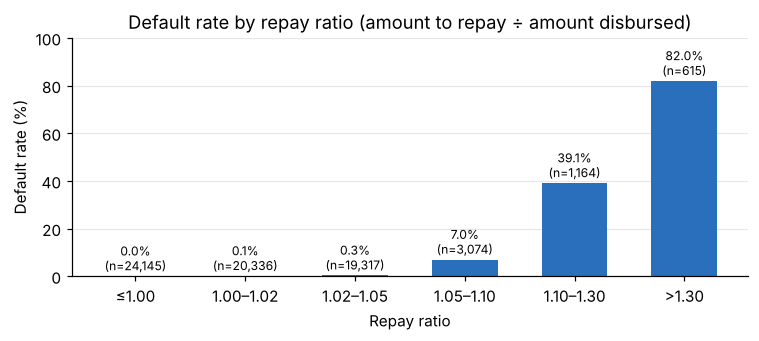

In [3]:
r = train.Total_Amount_to_Repay / train.Total_Amount
bins = [0, 1.0001, 1.02, 1.05, 1.10, 1.30, np.inf]; labels = ["≤1.00", "1.00–1.02", "1.02–1.05", "1.05–1.10", "1.10–1.30", ">1.30"]
t = train.groupby(pd.cut(r, bins, labels=labels)).target.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(7, 3.2)); b = ax.bar(t.index.astype(str), 100*t["mean"], color=BLUE, width=0.6)
ax.bar_label(b, [f"{100*m:.1f}%\n(n={n:,})" for m, n in zip(t["mean"], t["size"])], fontsize=8, padding=2)
ax.set(title="Default rate by repay ratio (amount to repay ÷ amount disbursed)", xlabel="Repay ratio", ylabel="Default rate (%)", ylim=(0, 100)); ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

The price of the loan is the strongest single signal: default rises from near 0% on low-ratio loans to over 80% above a 1.30 ratio. So features should describe *price, term and customer behaviour* — quantities that mean the same thing in any country — rather than Kenyan IDs.

## Step 3 — Feature engineering
Train and test are processed together. Design rules:
- **Currency-neutral**: amounts converted to USD with each country's yearly exchange rate from `economic_indicators.csv`; everything else is a ratio or a rate.
- **Market-aware**: annualised loan rate compared with local inflation and deposit rate.
- **Customer behaviour**: loan counts, gaps between loans, amount vs the customer's own norm — built from loan records only, never from labels.
- **No raw `lender_id` / `loan_type`**: Ghana's are unseen, so they are replaced by within-country frequency (share of the market).

In [4]:
def build_features(train, test, econ):
    df = pd.concat([train.assign(is_train=1), test.assign(is_train=0)], ignore_index=True)
    for c in ["disbursement_date", "due_date"]: df[c] = pd.to_datetime(df[c])
    df["year"] = df.disbursement_date.dt.year

    # --- macro table: one row per country-year, forward-filled to cover recent years
    m = econ.melt(["Country", "Indicator"], var_name="yr", value_name="v"); m["year"] = m.yr.str[2:].astype(int)
    m = m.pivot_table(index=["Country", "year"], columns="Indicator", values="v")
    m = m.rename(columns={"Inflation, consumer prices (annual %)": "inflation", "Official exchange rate (LCU per US$, period average)": "fx", "Deposit interest rate (%)": "deposit_rate"})[["inflation", "fx", "deposit_rate"]]
    full = pd.MultiIndex.from_product([m.index.levels[0], range(m.index.levels[1].min(), df.year.max() + 1)], names=["Country", "year"])
    m = m.reindex(full).groupby(level=0).ffill().reset_index()
    df = df.merge(m, left_on=["country_id", "year"], right_on=["Country", "year"], how="left").drop(columns="Country")

    # --- loan price and structure
    A, R = df.Total_Amount, df.Total_Amount_to_Repay
    df["amt_usd"] = A / df.fx;                       df["log_amt_usd"] = np.log1p(df.amt_usd)
    df["repay_ratio"] = R / A.replace(0, np.nan);    df["interest_usd"] = (R - A) / df.fx
    df["rate_per_day"] = (df.repay_ratio - 1) / df.duration.clip(lower=1)
    df["annual_rate"] = df.rate_per_day * 365 * 100
    df["real_rate"] = df.annual_rate - df.inflation; df["rate_vs_deposit"] = df.annual_rate - df.deposit_rate
    df["log_duration"] = np.log1p(df.duration);      df["is_new"] = (df.New_versus_Repeat == "New Loan").astype(int)
    df["lender_amt_usd"] = df.Amount_Funded_By_Lender / df.fx
    df["lender_repay_ratio"] = df.Lender_portion_to_be_repaid / df.Amount_Funded_By_Lender.replace(0, np.nan)
    df["lender_share_repay"] = df.Lender_portion_to_be_repaid / R.replace(0, np.nan)
    df["lender_zero"] = (df.Amount_Funded_By_Lender == 0).astype(int)
    df["n_lenders_on_loan"] = df.groupby("tbl_loan_id").lender_id.transform("nunique")

    # --- timing
    df["disb_month"] = df.disbursement_date.dt.month; df["disb_dow"] = df.disbursement_date.dt.dayofweek
    df["disb_dom"] = df.disbursement_date.dt.day;     df["due_dow"] = df.due_date.dt.dayofweek
    df["disb_ordinal"] = (df.disbursement_date - pd.Timestamp("2021-01-01")).dt.days

    # --- customer behaviour (one row per loan, ordered in time)
    L = df.drop_duplicates("tbl_loan_id").sort_values(["customer_id", "disbursement_date", "tbl_loan_id"]).copy(); g = L.groupby("customer_id")
    L["cust_n_loans"] = g.tbl_loan_id.transform("size");  L["cust_seq"] = g.cumcount()
    L["days_since_prev"] = g.disbursement_date.diff().dt.days
    L["days_to_next"] = -g.disbursement_date.diff(-1).dt.days
    L["prev_due_gap"] = (L.disbursement_date - g.due_date.shift()).dt.days
    L["cust_amt_mean"] = g.amt_usd.transform("mean");     L["cust_amt_max"] = g.amt_usd.transform("max")
    L["amt_vs_cust_mean"] = L.amt_usd / L.cust_amt_mean;  L["amt_vs_prev"] = L.amt_usd / g.amt_usd.shift()
    L["cust_ratio_mean"] = g.repay_ratio.transform("mean"); L["cust_ratio_max"] = g.repay_ratio.transform("max")
    L["ratio_vs_cust"] = L.repay_ratio - L.cust_ratio_mean; L["cust_dur_mean"] = g.duration.transform("mean")
    L["cust_span_days"] = (g.disbursement_date.transform("max") - g.disbursement_date.transform("min")).dt.days
    L["cust_n_types"] = g.loan_type.transform("nunique")
    new = [c for c in L.columns if c not in df.columns]
    df = df.merge(L[["tbl_loan_id"] + new], on="tbl_loan_id", how="left")

    # --- transferable replacements for raw IDs
    for c in ["lender_id", "loan_type"]:
        df[c + "_freq"] = df.groupby(["country_id", c])[c].transform("size") / df.groupby("country_id")[c].transform("size")
    return df

LOAN = ["log_amt_usd", "repay_ratio", "interest_usd", "rate_per_day", "annual_rate", "real_rate", "rate_vs_deposit", "duration", "log_duration", "is_new",
        "Lender_portion_Funded", "lender_amt_usd", "lender_repay_ratio", "lender_share_repay", "lender_zero", "n_lenders_on_loan"]
TIME = ["disb_month", "disb_dow", "disb_dom", "due_dow", "disb_ordinal"]
CUST = ["cust_n_loans", "cust_seq", "days_since_prev", "days_to_next", "prev_due_gap", "cust_amt_mean", "cust_amt_max", "amt_vs_cust_mean", "amt_vs_prev",
        "cust_ratio_mean", "cust_ratio_max", "ratio_vs_cust", "cust_dur_mean", "cust_span_days", "cust_n_types"]
FREQ = ["lender_id_freq", "loan_type_freq"]
FEATURES = LOAN + TIME + CUST + FREQ

data = build_features(train, test, econ)
tr = data[data.is_train == 1].reset_index(drop=True); te = data[data.is_train == 0].reset_index(drop=True); y = tr.target.values.astype(int)
print(len(FEATURES), "features |", tr.shape, te.shape)

38 features | (68654, 58) (18594, 58)


> **Note on scope.** Some customer features (`cust_n_loans`, `days_to_next`, customer means) look across a customer's whole loan history, including later loans. That is fine for this competition, where train and test are a random split of the same period. For live scoring at application time, restrict them to loans disbursed *before* the one being scored.

## Step 4 — Validation design
- **In-domain**: 5-fold `StratifiedGroupKFold`, grouped by `customer_id` so no customer sits on both sides of a split, stratified to keep the rare defaults in every fold.
- **Out-of-domain stress test**: train on the main lender only, score all other lenders. This imitates Ghana (unseen lenders, pricier and longer loans).

In [5]:
def best_f1(y_true, p):
    ts = np.linspace(0.02, 0.90, 89); f = [f1_score(y_true, p > t) for t in ts]; i = int(np.argmax(f)); return f[i], ts[i]

LGB_PARAMS = dict(objective="binary", n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, verbose=-1, n_jobs=2)
make_lgb = lambda seed: lgb.LGBMClassifier(**LGB_PARAMS, random_state=seed)
make_hgb = lambda seed: HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0, random_state=seed)

folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tr, y, tr.customer_id))
main = (tr.lender_id == tr.lender_id.mode()[0]).values

rows = []
for name, feats in {"loan only": LOAN, "+ timing": LOAN + TIME, "+ customer": LOAN + TIME + CUST, "+ id frequency (final)": FEATURES}.items():
    oof = np.zeros(len(tr))
    for a, b in folds: oof[b] = make_lgb(SEED).fit(tr.loc[a, feats], y[a]).predict_proba(tr.loc[b, feats])[:, 1]
    p_ood = make_lgb(SEED).fit(tr.loc[main, feats], y[main]).predict_proba(tr.loc[~main, feats])[:, 1]
    rows.append({"features": name, "n": len(feats), "CV F1": best_f1(y, oof)[0], "CV AUC": roc_auc_score(y, oof), "unseen-lender F1": best_f1(y[~main], p_ood)[0], "unseen-lender AUC": roc_auc_score(y[~main], p_ood)})
pd.DataFrame(rows).round(4)

,features,n,CV F1,CV AUC,unseen-lender F1,unseen-lender AUC
0,loan only,16,0.8285,0.9923,0.7858,0.9697
1,+ timing,21,0.8531,0.9960,0.8442,0.9841
2,+ customer,36,0.8704,0.9963,0.8789,0.9886
3,+ id frequency (final),38,0.8717,0.9964,0.8784,0.9895


Each feature block improves both the in-domain score and the unseen-lender score, so the final set generalises rather than memorising Kenyan lenders.

## Step 5 — Train the models
Two gradient-boosting libraries (LightGBM averaged over 3 seeds, and scikit-learn's HistGradientBoosting), blended 50/50. No resampling or class weights: they distort probabilities, and the imbalance is handled by the decision threshold in Step 6.

In [6]:
LGB_SEEDS = [42, 7, 2024]
oof_lgb, oof_hgb = np.zeros(len(tr)), np.zeros(len(tr))
for k, (a, b) in enumerate(folds):
    Xa, Xb = tr.loc[a, FEATURES], tr.loc[b, FEATURES]
    oof_lgb[b] = np.mean([make_lgb(s).fit(Xa, y[a]).predict_proba(Xb)[:, 1] for s in LGB_SEEDS], axis=0)
    oof_hgb[b] = make_hgb(SEED).fit(Xa, y[a]).predict_proba(Xb)[:, 1]
    print(f"fold {k+1}: LGB AUC {roc_auc_score(y[b], oof_lgb[b]):.4f} | HGB AUC {roc_auc_score(y[b], oof_hgb[b]):.4f}")
oof = 0.5 * oof_lgb + 0.5 * oof_hgb
pd.DataFrame([{"model": n, "F1 (best threshold)": best_f1(y, p)[0], "threshold": best_f1(y, p)[1], "ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p)}
              for n, p in [("LightGBM", oof_lgb), ("HistGB", oof_hgb), ("Blend", oof)]]).round(4)

fold 1: LGB AUC 0.9965 | HGB AUC 0.9928


fold 2: LGB AUC 0.9952 | HGB AUC 0.9931


fold 3: LGB AUC 0.9970 | HGB AUC 0.9977


fold 4: LGB AUC 0.9984 | HGB AUC 0.9984


fold 5: LGB AUC 0.9965 | HGB AUC 0.9944


,model,F1 (best threshold),threshold,ROC AUC,PR AUC
0,LightGBM,0.8703,0.41,0.9967,0.9347
1,HistGB,0.8705,0.39,0.9951,0.9365
2,Blend,0.8780,0.38,0.9957,0.9379


## Step 6 — Choose the decision threshold for F1
The threshold is picked on out-of-fold predictions, then checked fold by fold to see how stable it is.

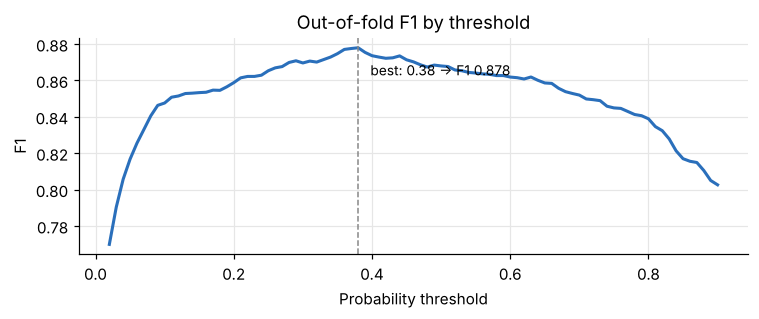

threshold 0.38 | F1 0.8780 | precision 0.8840 | recall 0.8720
F1 per fold at this threshold: [0.906, 0.84, 0.879, 0.846, 0.917]
F1 on non-main lenders (out-of-fold): 0.872 | on new loans: 0.9328


In [7]:
F1_CV, THR = best_f1(y, oof)
ts = np.linspace(0.02, 0.90, 89)
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(ts, [f1_score(y, oof > t) for t in ts], color=BLUE, lw=2); ax.axvline(THR, color="#888", ls="--", lw=1)
ax.annotate(f"best: {THR:.2f} → F1 {F1_CV:.3f}", (THR, F1_CV), xytext=(8, -18), textcoords="offset points", fontsize=9)
ax.set(title="Out-of-fold F1 by threshold", xlabel="Probability threshold", ylabel="F1"); plt.tight_layout(); plt.show()
pred = oof > THR
print(f"threshold {THR:.2f} | F1 {F1_CV:.4f} | precision {precision_score(y, pred):.4f} | recall {recall_score(y, pred):.4f}")
print("F1 per fold at this threshold:", [round(f1_score(y[b], oof[b] > THR), 3) for _, b in folds])
print("F1 on non-main lenders (out-of-fold):", round(f1_score(y[~main], oof[~main] > THR), 4), "| on new loans:", round(f1_score(y[tr.is_new == 1], oof[(tr.is_new == 1).values] > THR), 4))

## Step 7 — What drives the predictions

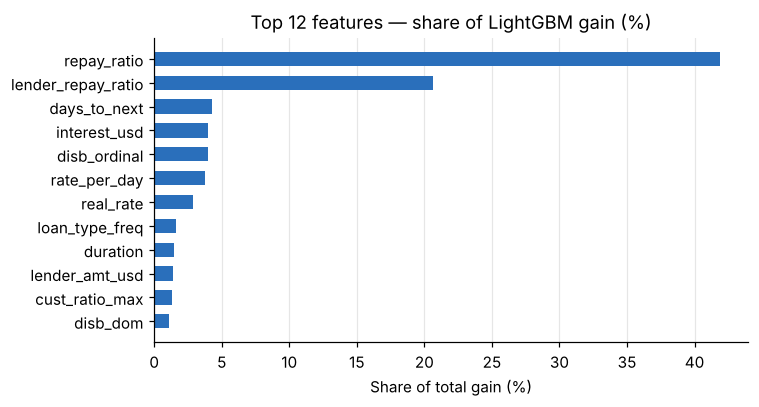

In [8]:
full_lgb = [make_lgb(s).fit(tr[FEATURES], y) for s in LGB_SEEDS]; full_hgb = make_hgb(SEED).fit(tr[FEATURES], y)
imp = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in full_lgb], axis=0), FEATURES); imp = (100 * imp / imp.sum()).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.barh(imp.index, imp.values, color=BLUE, height=0.6); ax.grid(axis="y", visible=False)
ax.set(title="Top 12 features — share of LightGBM gain (%)", xlabel="Share of total gain (%)"); plt.tight_layout(); plt.show()

## Step 8 — Predict the test set and write the submission
One extra rule: a loan funded by several lenders appears once per lender with the same outcome, so a test row whose `tbl_loan_id` also appears in train takes that loan's known label. The cell first measures how reliable that is inside train.

In [9]:
p_test = 0.5 * np.mean([m.predict_proba(te[FEATURES])[:, 1] for m in full_lgb], axis=0) + 0.5 * full_hgb.predict_proba(te[FEATURES])[:, 1]
label = (p_test > THR).astype(int)

multi = tr[tr.duplicated("tbl_loan_id", keep=False)].groupby("tbl_loan_id").target.nunique()
print(f"Train loans with several lenders: {len(multi)}, same outcome for all lenders: {100 * (multi == 1).mean():.1f}%")
known = te.tbl_loan_id.map(tr.groupby("tbl_loan_id").target.max())
changed = int((known.notna() & (known.fillna(0) != label)).sum())
label = np.where(known.notna(), known.fillna(0), label).astype(int)
print(f"Test rows sharing a loan with train: {int(known.notna().sum())}, labels changed by the rule: {changed}")

sub = pd.DataFrame({"ID": te.ID, "target": label}); sub.to_csv("submission.csv", index=False)
pd.DataFrame({"ID": te.ID, "probability": p_test}).to_csv("test_probabilities.csv", index=False)
print(sub.shape, "| predicted default rate by country:"); print(sub.assign(country=te.country_id).groupby("country").target.agg(["size", "sum", "mean"]).round(4))

Train loans with several lenders: 2134, same outcome for all lenders: 99.9%
Test rows sharing a loan with train: 920, labels changed by the rule: 5
(18594, 2) | predicted default rate by country:
          size  sum    mean
country                    
Ghana     3525  383  0.1087
Kenya    15069  281  0.0186


## Step 9 — Credit scoring function
Required from the top 10. The recipe:
1. **Calibrate** the blended output to a real probability of default (PD) with Platt scaling (a 2-parameter logistic fit) on the out-of-fold predictions.
2. **Scale** to a familiar score: `score = 600 + 50·log2(odds / 50)`, where odds = (1−PD)/PD. So 600 means 50:1 odds of repaying, and every +50 points doubles the odds. Clipped to 300–850.
3. **Bin** into five risk bands at fixed PD cut-offs (0.5%, 2%, 10%, 40%), each with a suggested action. The table checks that observed default rates rise band by band and sit near the predicted PD.

In [10]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
calibrator = LogisticRegression(C=1e6).fit(logit(oof).reshape(-1, 1), y)   # Platt scaling: 2 parameters, smooth and monotone
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 50
# band edges sit at PD = 0.5%, 2%, 10%, 40%  ->  scores 700, 600, 475, 350
BANDS = [(-np.inf, 350, "E - Very high risk", "Decline"), (350, 475, "D - High risk", "Decline or secure / manual review"), (475, 600, "C - Medium risk", "Approve with lower limit, shorter term"),
         (600, 700, "B - Low risk", "Approve"), (700, np.inf, "A - Very low risk", "Approve, eligible for limit increase")]

def credit_score(raw_prob):
    """Model output -> DataFrame with calibrated PD, 300-850 score, risk band and action."""
    pd_ = np.clip(calibrator.predict_proba(logit(np.asarray(raw_prob)).reshape(-1, 1))[:, 1], 1e-4, 1 - 1e-4)
    score = np.clip(BASE_SCORE + PDO * np.log2(((1 - pd_) / pd_) / BASE_ODDS), 300, 850).round().astype(int)
    out = pd.DataFrame({"pd": pd_, "score": score})
    for lo, hi, band, action in BANDS:
        mask = (out.score >= lo) & (out.score < hi); out.loc[mask, "band"] = band; out.loc[mask, "action"] = action
    return out

sc = credit_score(oof).assign(default=y)
print("Brier score raw %.5f -> calibrated %.5f" % (brier_score_loss(y, oof), brier_score_loss(y, sc.pd)))
tbl = sc.groupby("band").agg(loans=("default", "size"), share=("default", lambda s: len(s) / len(sc)), min_score=("score", "min"), max_score=("score", "max"), avg_pd=("pd", "mean"), observed_default_rate=("default", "mean"), defaults=("default", "sum"))
tbl["share_of_all_defaults"] = tbl.defaults / tbl.defaults.sum(); tbl.round(4)

Brier score raw 0.00359 -> calibrated 0.00354


,loans,share,min_score,max_score,avg_pd,observed_default_rate,defaults,share_of_all_defaults
band,,,,,,,,
A - Very low risk,65215,0.9499,700,850,0.0005,0.0003,17,0.0135
B - Low risk,1188,0.0173,600,699,0.0097,0.0210,25,0.0199
C - Medium risk,643,0.0094,475,599,0.0463,0.0607,39,0.0310
D - High risk,330,0.0048,350,474,0.2120,0.2182,72,0.0572
E - Very high risk,1278,0.0186,300,349,0.8728,0.8646,1105,0.8784


In [11]:
test_scores = pd.concat([te[["ID", "country_id"]], credit_score(p_test)], axis=1); test_scores.to_csv("test_credit_scores.csv", index=False)
display(test_scores.groupby(["country_id", "band"]).size().unstack(fill_value=0))
test_scores.head()

band,A - Very low risk,B - Low risk,C - Medium risk,D - High risk,E - Very high risk
country_id,,,,,
Ghana,3026,22,30,48,399
Kenya,14312,260,131,76,290


,ID,country_id,pd,score,band,action
0,ID_269404226088267278,Kenya,0.000531,850,A - Very low risk,"Approve, eligible for limit increase"
1,ID_255356300042267278,Kenya,0.000309,850,A - Very low risk,"Approve, eligible for limit increase"
2,ID_257026243764267278,Kenya,0.000366,850,A - Very low risk,"Approve, eligible for limit increase"
3,ID_264617299409267278,Kenya,0.000339,850,A - Very low risk,"Approve, eligible for limit increase"
4,ID_247613296713267278,Kenya,0.000320,850,A - Very low risk,"Approve, eligible for limit increase"


## Where to go next
- **Ghana is the main risk.** Nothing in train is labelled Ghanaian, so its threshold cannot be validated. The unseen-lender test shows ranking transfers well but the best cut-off moves; compare leaderboard scores for a few thresholds on Ghana rows only.
- Tune LightGBM (Optuna) and add CatBoost/XGBoost to the blend.
- Try pseudo-labelling confident test rows to adapt to Ghana.
- For production, rebuild customer features point-in-time and drop the same-loan rule.